# Imports

In [ ]:
%matplotlib inline

In [ ]:
from perceval.components.unitary_components import PS, BS
from perceval.rendering.circuit import DisplayConfig, SymbSkin
import numpy as np
from pathlib import Path
from collections import defaultdict
import perceval as pcvl
from perceval import BasicState
import os
import glob
import time
from datetime import datetime
from tqdm import tqdm
import scipy as sc
import itertools as it
from scipy.optimize import minimize

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.ticker import FormatStrFormatter
from tqdm.auto import tqdm

from scipy.optimize import minimize, OptimizeResult
from scipy.optimize import dual_annealing
from uncertainties import unumpy
import ipywidgets as widgets
from IPython.display import display, clear_output
from uncertainties import ufloat

# Circuit Design

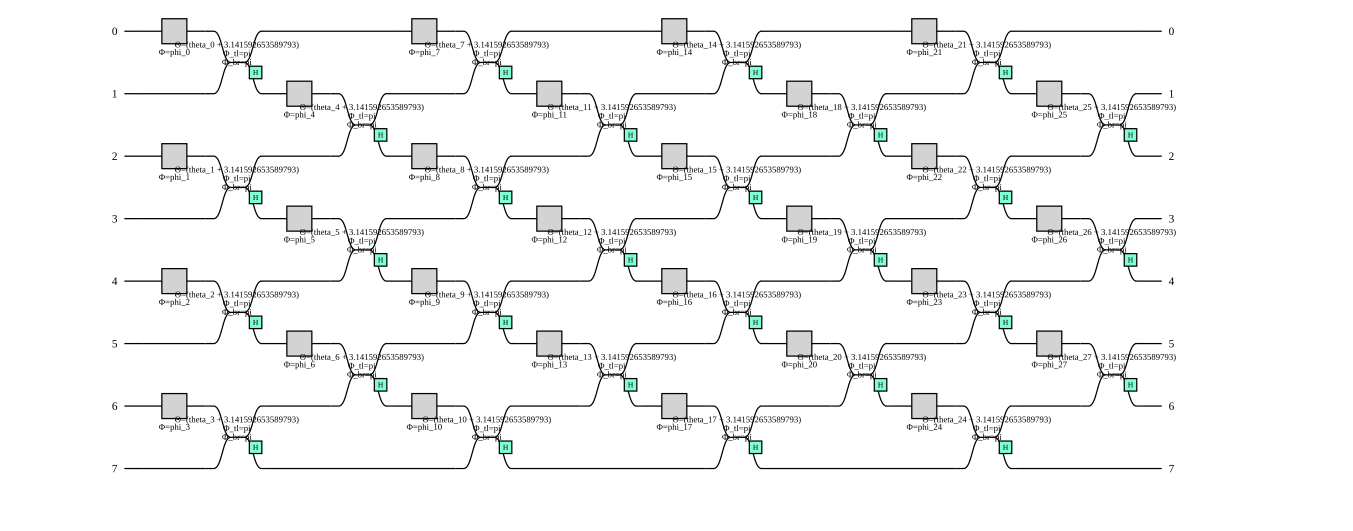

In [ ]:
m = 8

circuit = pcvl.components.GenericInterferometer(m,
                                fun_gen = lambda idx: (pcvl.Circuit(2, name='mzi')
                                                       .add(0, PS(pcvl.P(f"phi_{idx}"))))
                                                       .add(0, BS.H(theta=pcvl.P(f"theta_{idx}") + np.pi, phi_tl = np.pi, phi_br = np.pi)),
                                                shape= pcvl.InterferometerShape.RECTANGLE)
symbolic_skin = SymbSkin(compact_display=True)
pcvl.pdisplay(circuit, skin=symbolic_skin)

# Parameters, Input and Output States

In [ ]:
parameters = circuit.get_parameters()
par_e = parameters[::2]
par_i = parameters[1::2]

## 8 modes

In [ ]:
# 8 modes
out_states = [[1,0,1,0],[1,0,0,1],[0,1,1,0],[0,1,0,1]]
out_states = [[0,0]+j+[0]*2 for j in out_states]
out_states = [pcvl.BasicState(i) for i in out_states]
out_states

[|0,0,1,0,1,0,0,0>, |0,0,1,0,0,1,0,0>, |0,0,0,1,1,0,0,0>, |0,0,0,1,0,1,0,0>]

In [ ]:
V = 1

x = np.arccos(2*V-1)
v1 = BasicState("|{0}>")
v2 = pcvl.StateVector("|{1}>")
phase = complex(np.exp(1j*x))
in_state = BasicState("|0,0>")*(v1+v2)*BasicState("|0>")*(v1+phase*v2)*BasicState("|0,0,0>")
in_state

0.5*|0,0,{1},0,{1},0,0,0>+0.5*|0,0,{1},0,{0},0,0,0>+0.5*|0,0,{0},0,{1},0,0,0>+0.5*|0,0,{0},0,{0},0,0,0>

# Simulation Functions



## Circuit Simulation

In [ ]:
processor = pcvl.Processor("Naive")

In [ ]:
calls = 0
rng = np.random.default_rng()

def circ_sim(f_i, f_e, n_shots=1e9):
    global calls
    calls += 1

    for i,p in enumerate(par_e):
        p.set_value(f_e[i])

    for j,q in enumerate(par_i):
        q.set_value(f_i[j])

    processor.set_circuit(circuit)
    simulator = pcvl.SimulatorFactory().build(processor)

    P_I = [] 

    for s in out_states:
        p_I = simulator.probability(in_state,s)
        P_I.append(p_I)

    PP = np.array(P_I, dtype=float)
    CC = rng.poisson(PP*n_shots)

    return CC

def circ_sim_prob(f_i, f_e, n_shots=1e9):
    global calls
    calls += 1

    for i,p in enumerate(par_e):
        p.set_value(f_e[i])

    for j,q in enumerate(par_i):
        q.set_value(f_i[j])

    processor.set_circuit(circuit)
    simulator = pcvl.SimulatorFactory().build(processor)

    P_I = [] 

    for s in out_states:
        p_I = simulator.probability(in_state,s)
        P_I.append(p_I)

    PP = np.array(P_I)

    return PP

## Measurement function

In [ ]:
def prepare_qubit(theta, phi, state, bs, ps):
    theta[bs] = 2*np.arcsin(np.abs(state[0]))
    phi[ps] = np.angle(state[1]) - np.angle(state[0])
    # print(f'prepared {state} as ')
    # print(theta[bs], phi[ps])
    return theta, phi
        
def P_calc(x, measurement_group, input_states, scheme='qlass'):
    
    if scheme == 'qlass_8modes':
        N_modes = 8
        N_parameters = int(N_modes*(N_modes-1)/2)
        theta_par = [8,9,15,16]
        theta_cnot = [11,12,13]
        theta_meas = [22,23]
        phi_meas = [22,23]
        offset_phases = [8,9,19,20]
        state0_bs = 1
        state0_ps = 5
        state1_bs = 2
        state1_ps = 6
        
        # chip initialization
        theta = np.full(N_parameters,np.pi)
        phi = np.zeros(N_parameters)

        # prepare ansatz
        prepare_qubit(theta, phi, input_states[0], state0_bs, state0_ps)
        prepare_qubit(theta, phi, input_states[1], state1_bs, state1_ps)
        
        # set internal and external phases
        theta[theta_cnot] = [-np.arccos(1/3),-np.arccos(1/3),np.arccos(1/3)]
        theta[theta_par] = x + np.pi
        phi[offset_phases] = np.pi

    meas_circ = {'I': {'phi': [0], 'theta': [np.pi]},
                 'X': {'phi': [0], 'theta': [np.pi/2]},
                 'Y': {'phi': [np.pi/2], 'theta': [np.pi/2]},
                 'Z': {'phi': [0], 'theta': [np.pi]}}

    results = {}
    for op in measurement_group:
        theta[theta_meas] = meas_circ[op[0]]['theta'] + meas_circ[op[1]]['theta']
        phi[phi_meas] = meas_circ[op[0]]['phi'] + meas_circ[op[1]]['phi']
        results[op] = circ_sim(theta, phi, n_shots=SHOTS)
    return results

## Hamiltonian and gradient computation

In [ ]:
def expected_value(cc, A, B, eig, tot=None):
    signs = np.kron(eig[A], eig[B])
    if tot == None:
        tot = cc.sum()
    if tot == 0:
        return 0
    return (signs * cc).sum() / tot

def S1(x, H_terms, measurement_groups, input_states, Error = False, scheme = 'qlass'):

    n = len(x)

    results = P_calc(x, measurement_groups, input_states, scheme = scheme)
    if Error:
        results = {k: unumpy.uarray(v, np.sqrt(v + 1)) for k, v in results.items()}
        
    # Hamiltonian computation

    eig = {'I': np.array([1,  1]),
           'X': np.array([1, -1]),
           'Y': np.array([1, -1]),
           'Z': np.array([1, -1])}
    
    pauli_groupings = {'II': 'II', 'IX': 'XX', 'IY': 'YY', 'IZ': 'ZZ',
                       'XI': 'XX', 'XX': 'XX', 'XY': 'XY', 'XZ': 'XZ',
                       'YI': 'YY', 'YX': 'YX', 'YY': 'YY', 'YZ': 'YZ',
                       'ZI': 'ZZ', 'ZX': 'ZX', 'ZY': 'ZY', 'ZZ': 'ZZ'}
     
    exp_values = ({op: expected_value(results[pauli_groupings[op]],op[0],op[1],eig) for op in H_terms if op != 'II'})
    exp_values['II'] = 1

    coeffs = np.array(list(H_terms.values()))
    expval  = np.array([exp_values[op] for op in H_terms])
    H = coeffs @ expval

    # gradient computation
    if not Error:
        grad_H = []
        for i in range(n):
            x_s = np.copy(x)
            x_s[i] += np.pi/2
            res1 = P_calc(x_s, measurement_groups, input_states, scheme = scheme)
            
            x_s = np.copy(x)
            x_s[i] -= np.pi/2
            res2 = P_calc(x_s, measurement_groups, input_states, scheme = scheme)

            dres = {op: (res1[op] - res2[op])/2 for op in measurement_groups}
            dres['II'] = np.array([0])
            
            dexp_values = ({op: expected_value(dres[pauli_groupings[op]],op[0],op[1],eig, tot=results[pauli_groupings[op]].sum()) - exp_values[op] * dres[pauli_groupings[op]].sum() / results[pauli_groupings[op]].sum() for op in H_terms if op != 'II'})
            dexp_values['II'] = 0
            dexpval = np.array([dexp_values[op] for op in H_terms])
            dH = coeffs @ dexpval
            grad_H.append(dH)
            
        return H, np.array(grad_H)
    else:
        return H.nominal_value, H.std_dev

def S(x, H_terms, measurement_groups, input_states, weights, scheme):
    H1, Grad1 = S1(x, H_terms, measurement_groups, input_states[0], Error=False, scheme = scheme)
    H2, Grad2 = S1(x, H_terms, measurement_groups, input_states[1], Error=False, scheme = scheme)
    return weights[0]*H1 + weights[1]*H2, weights[0]*Grad1 + weights[1]*Grad2

In [ ]:
def expected_value(cc, A, B, eig, tot=None):
    signs = np.kron(eig[A], eig[B])
    if tot == None:
        tot = cc.sum()
    return (signs * cc).sum() / tot

eig = {'I': np.array([1,  1]),
           'X': np.array([1, -1]),
           'Y': np.array([1, -1]),
           'Z': np.array([1, -1])}
    
pauli_groupings = {'II': 'ZZ', 'IX': 'XX', 'IY': 'YY', 'IZ': 'ZZ',
                   'XI': 'XX', 'XX': 'XX', 'XY': 'XY', 'XZ': 'XZ',
                   'YI': 'YY', 'YX': 'YX', 'YY': 'YY', 'YZ': 'YZ',
                   'ZI': 'ZZ', 'ZX': 'ZX', 'ZY': 'ZY', 'ZZ': 'ZZ'}

def S1_energy(x, H_terms, measurement_groups, input_states, Error = False, scheme = 'qlass'):
    
    n = len(x)

    results = P_calc(x, measurement_groups, input_states, scheme = scheme)
    
    if Error:
        results = {k: unumpy.uarray(v, np.sqrt(v + 1)) for k, v in results.items()}
        
    # Hamiltonian computation

    exp_values = ({op: expected_value(results[pauli_groupings[op]],op[0],op[1],eig) for op in H_terms})# if op != 'II'})

    coeffs = np.array(list(H_terms.values()))
    expval  = np.array([exp_values[op] for op in H_terms])
    H = coeffs @ expval
    if not Error:
        return H
    else:
        return H.nominal_value, H.std_dev

def S_energy(x, H_terms, measurement_groups, input_states, weights, scheme = 'qlass'):
    H1 = S1_energy(x, H_terms, measurement_groups, input_states[0], Error=False, scheme = scheme)
    H2 = S1_energy(x, H_terms, measurement_groups, input_states[1], Error=False, scheme = scheme)
    return weights[0]*H1 + weights[1]*H2

In [ ]:
sigma = {'I': np.array([[1,0],[0,1]], dtype=complex),
         'X': np.array([[0,1],[1,0]], dtype=complex),
         'Y': np.array([[0,-1j],[1j,0]], dtype=complex),
         'Z': np.array([[1,0],[0,-1]], dtype=complex)}

def hamiltonian_matrix(H_terms, dim=4):
    
    H = np.zeros((dim,dim), dtype=complex)
    for pauliop, coeff in H_terms.items():
        O = np.kron(sigma[pauliop[0]],sigma[pauliop[1]])
        H += coeff * O
    eigenvalues = np.sort(np.linalg.eigvals(H)).real
    return H, eigenvalues

In [ ]:
def ground_state(x, H_terms, measurement_groups, input_states, scheme = 'qlass'):
    H1 = S1_energy(x, H_terms, measurement_groups, input_states[0], Error=False, scheme = scheme)
    # H2 = S1_energy(x, H_terms, measurement_groups, inv=True, Error=False, scheme = scheme)
    return H1

def excited_state(x, H_terms, measurement_groups, input_states, scheme = 'qlass'):
    # H1 = S1_energy(x, H_terms, measurement_groups, input_states, Error=False, scheme = scheme)
    H2 = S1_energy(x, H_terms, measurement_groups, input_states[0], Error=False, scheme = scheme)
    return H2

## Quantum State Tomography

In [ ]:
complete_meas = ['XX', 'YY', 'ZZ', 'YX', 'ZX', 'XY', 'ZY', 'XZ', 'YZ']
pauli_groupings = {'II': 'ZZ', 'IX': 'XX', 'IY': 'YY', 'IZ': 'ZZ',
                   'XI': 'XX', 'XX': 'XX', 'XY': 'XY', 'XZ': 'XZ',
                   'YI': 'YY', 'YX': 'YX', 'YY': 'YY', 'YZ': 'YZ',
                   'ZI': 'ZZ', 'ZX': 'ZX', 'ZY': 'ZY', 'ZZ': 'ZZ'}
eig = {'I': np.array([1,  1]),
       'X': np.array([1, -1]),
       'Y': np.array([1, -1]),
       'Z': np.array([1, -1])}
pauli = {'I': np.array([[1,0],[0,1]], dtype=complex),
         'X': np.array([[0,1],[1,0]], dtype=complex),
         'Y': np.array([[0,-1j],[1j,0]], dtype=complex),
         'Z': np.array([[1,0],[0,-1]], dtype=complex)}

def qst(x, input_states, Error=True, scheme = 'qlass'):
    n = len(input_states)
    rhos = np.zeros((2,4,4), dtype=complex)

    for i in range(n):
        results = P_calc(x, complete_meas, input_states[i], scheme = scheme)
        if Error:
            results = {k: unumpy.uarray(v, np.sqrt(v + 1)) for k, v in results.items()}
            
        ev = {}
        for op in pauli_groupings:
            ev[op] = expected_value(results[pauli_groupings[op]], op[0], op[1], eig)
        
        for op in ev:
            rhos[i] += ev[op] * np.kron(pauli[op[0]], pauli[op[1]])
        rhos[i] = rhos[i]/4
        
    return rhos

## Density matrix

In [ ]:
def plot_density(density, ax, title="Electron Density"):
    im = ax.imshow(density, cmap="plasma")
    for i in range(density.shape[0]):
        for j in range(density.shape[1]):
            ax.text(j, i, f"{density[i, j]:.6f}", ha='center', va='center', color='red')
    ax.figure.colorbar(im, ax=ax, label="Density")
    ax.set_title(title)
    ax.set_xlabel(f"x_2 grid index")
    ax.set_ylabel(f"x_1 grid index")

## Fidelity

In [ ]:
def fidelity(rho, sigma):
    return (np.trace(sc.linalg.sqrtm(sc.linalg.sqrtm(rho) @ sigma @ sc.linalg.sqrtm(rho))).real)**2

In [ ]:
def pad_and_stack(arrs):
    max_len = max(len(a) for a in arrs)
    padded = np.empty((len(arrs), max_len))
    for j, a in enumerate(arrs):
        padded[j, :len(a)] = a
        padded[j, len(a):] = a[-1] 
    return padded

# Simulation with exposure and visibility

In [ ]:
V = 0.88

x = np.arccos(2*V-1)
v1 = BasicState("|{0}>")
v2 = pcvl.StateVector("|{1}>")
phase = complex(np.exp(1j*x))
in_state = BasicState("|0,0>")*(v1+v2)*BasicState("|0>")*(v1+phase*v2)*BasicState("|0,0,0>")
in_state

(0.38+0.325I)*|0,0,{1},0,{1},0,0,0>+0.5*|0,0,{1},0,{0},0,0,0>+(0.38+0.325I)*|0,0,{0},0,{1},0,0,0>+0.5*|0,0,{0},0,{0},0,0,0>

In [ ]:
N = 6 # six hamiltonians

SCHEME = 'qlass_8modes'

if SCHEME == '10parameters':
    N_par = 10
if SCHEME == 'qlass_8modes' or SCHEME == 'qlass':
    N_par = 4

n_qubits = 2
n_occ = 2 # number of occupied states

dim = 2 ** n_qubits
input_states = [[[np.sqrt(1/2),np.sqrt(1/2)],[np.sqrt(1/2),np.sqrt(1/2)]],
                [[np.sqrt(1/2),-np.sqrt(1/2)],[np.sqrt(1/2),-np.sqrt(1/2)]]]   # |++>, |-->

measurement_groups = ['ZZ', 'XX', 'XZ', 'ZX', 'YY']
weights = [0.5,0.5]

H_1 = {'II': -0.44216633, 'IX':-0.2458943, 'IZ':-0.36997974, 'XI':-0.07340748, 'XX':0.00097788, 'XZ':0.07417185, 'YY': 0.03523796, 'ZI':-0.44476681, 'ZX':-0.04444575, 'ZZ':-0.41780773}
H_2 = {'II': -0.36108472, 'IX': -0.24059126, 'IZ': -0.43150506, 'XI': -0.07147771, 'XX': 0.01069059, 'XZ': 0.07981971, 'YY': 0.04986396, 'ZI': -0.50711419, 'ZX': -0.0509102, 'ZZ': -0.38530931}
H_3 = {'II': -0.38614239, 'IX': -0.24216967, 'IZ': -0.40039876, 'XI': -0.0707107, 'XX': 0.0068053, 'XZ': 0.07767017, 'YY': 0.04396768, 'ZI': -0.47647139, 'ZX': -0.04831784, 'ZZ': -0.40068126}
H_4 = {'II': -0.38221333, 'IX': -0.2420531, 'IZ': -0.40161551, 'XI': -0.0699407, 'XX': 0.006038, 'XZ': 0.07767811, 'YY': 0.0434773, 'ZI': -0.47938523, 'ZX': -0.04853032, 'ZZ': -0.40110755}
H_5 = {'II': -0.38213293, 'IX': -0.24207902, 'IZ': -0.40149067, 'XI': -0.06991539, 'XX': 0.00599192, 'XZ': 0.07766414, 'YY': 0.04343264, 'ZI': -0.47941926, 'ZX': -0.04850277, 'ZZ': -0.40114839}
H_6 = {'II': -0.3821493, 'IX': -0.24208486, 'IZ': -0.40144943, 'XI': -0.06991077, 'XX': 0.005983, 'XZ': 0.07765853, 'YY': 0.04342284, 'ZI': -0.47941549, 'ZX': -0.04849506, 'ZZ': -0.40116524}

H_all = [H_1, H_2, H_3, H_4, H_5, H_6]

D_1 = np.array([[ 0.97835306,  0.12862265, -0.04958019, -0.04665151],
 [ 0.12862265,  0.22317224,  0.20270098,  0.34019835],
 [-0.04958019,  0.20270098,  0.21473099,  0.35366045],
 [-0.04665151,  0.34019835,  0.35366045,  0.58374371]])
D_2 = np.array([[ 0.9878844,   0.07607518, -0.06000756, -0.05079833],
 [ 0.07607518,  0.4988745,   0.26283086,  0.41848685],
 [-0.06000756,  0.26283086,  0.14873269,  0.23222901],
 [-0.05079833,  0.41848685,  0.23222901,  0.3645084 ]])
D_3 = np.array([[ 0.98188639,  0.10905999, -0.05921594, -0.04883543],
 [ 0.10905999,  0.32303148,  0.24635457,  0.38222701],
 [-0.05921594,  0.24635457, 0.20933125,  0.3182995 ],
 [-0.04883543,  0.38222701,  0.3182995,   0.48575088]])
D_4 = np.array([[ 0.98232503,  0.10681234, -0.05941084, -0.04923454],
 [ 0.10681234,  0.33397883,  0.24847078,  0.38638112],
 [-0.05941084,  0.24847078,  0.20519619,  0.31276723],
 [-0.04923454,  0.38638112,  0.31276723,  0.47849995]])
D_5 = np.array([[ 0.9823311,   0.10675749, -0.05940946, -0.04929565],
 [ 0.10675749,  0.33439568,  0.24828949,  0.38669158],
 [-0.05940946,  0.24828949,  0.20463638,  0.31238306],
 [-0.04929565,  0.38669158,  0.31238306,  0.47863684]])
D_6 = np.array([[ 0.98231588,  0.10678212, -0.05949151, -0.04929233],
 [ 0.10678212,  0.33456497,  0.24835864,  0.38671283],
 [-0.05949151,  0.24835864,  0.20467012,  0.31234437],
 [-0.04929233,  0.38671283,  0.31234437,  0.47844903]])

D_all = [D_1, D_2, D_3, D_4, D_5, D_6]

In [ ]:
colors = ['#0081A7',
          '#00AFB9',
          '#A8DADC',
          '#FED9B7',
          '#F4A261',
          '#F07167']

def callback(x, H_terms, measurement_groups, input_states, weights, E0_true, E1_true):
    v1,e1 = S1_energy(x, H_terms, measurement_groups, input_states[0], Error = True, scheme = SCHEME)
    v2,e2 = S1_energy(x, H_terms, measurement_groups, input_states[1], Error = True, scheme = SCHEME)

    cost.append(weights[0]*v1 + weights[1]*v2)

In [ ]:
plot_outputs = widgets.Output()
text_outputs = widgets.Output()
trace_outputs = widgets.Output()
exposure_output = widgets.Output()

In [ ]:
display(text_outputs)

In [ ]:
display(plot_outputs)

In [ ]:
display(trace_outputs)

In [ ]:
display(exposure_output)

## Loop

In [ ]:
# loop on 6 hamiltonians
os.makedirs(f'../Simulations/8-mode chip/shots_visibility/', exist_ok=True)

N = 6
N_trials = 100
error_threshold = 0.1
max_attempts = 0
exposure_range = [1e0,1e1,1e2,1e3,1e4,1e5,1e6,1e7,1e8,1e9] #np.arange(1,101)
vis_range = np.linspace(0.8,1.0,5)
accuracy = np.empty((N,len(exposure_range),len(vis_range),N_trials))


for j, t in tqdm(enumerate(exposure_range[9:], start=9)):
    SHOTS = 20_000*t
    for i in tqdm(range(N)):
        for vv, V in tqdm(enumerate(vis_range)):
            x = np.arccos(2*V-1)
            v1 = BasicState("|{0}>")
            v2 = pcvl.StateVector("|{1}>")
            phase = complex(np.exp(1j*x))
            in_state = BasicState("|0,0>")*(v1+v2)*BasicState("|0>")*(v1+phase*v2)*BasicState("|0,0,0>")
            
            for trial in tqdm(range(N_trials)):
                
                H_matrix, energies = hamiltonian_matrix(H_all[i], dim)
                cost_th = weights[0]*energies[0] + weights[1]*energies[1]
                attempt = 0
                while True:
                    r0 = np.random.uniform(0,2*np.pi,N_par)
                    calls = 0
                    cost = []
                    E1 = []
                    E2 = []
                    cost_e = []
                    E1_e = []
                    E2_e = []
                    trace = []
                    trace_e = []
                    
                    res = minimize(S_energy, x0 = r0, args = (H_all[i], measurement_groups, input_states, weights, SCHEME), method = 'COBYLA', callback = lambda x: callback(x, H_all[i], measurement_groups, input_states, weights, energies[0], energies[1]))
                    optimized_parameters = res.x
                    rho = qst(optimized_parameters, input_states, Error=False, scheme = 'qlass_8modes')
                    density = rho[0]+rho[1]
                    error_D = np.abs(D_all[i] - density.real)
                    with trace_outputs:
                        clear_output(wait=True)
                        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
                        plot_density(density.real, axes[0], "Electron Density")
                        plot_density(error_D, axes[1], "Error")
                        fig.tight_layout()
                        display(fig)
                        plt.close(fig)
                    final_error = error_D.max()
                    attempt += 1
                    if final_error < error_threshold or attempt >= max_attempts:
                            break
                accuracy[i,j,vv,trial] = cost[-1] - cost_th
        np.savez(f'../Simulations/8-mode chip/shots_visibility/simulation_{N_trials}.npz', visibility=vis_range, exposure=exposure_range, accuracy=accuracy)
    
    with exposure_output:
        clear_output(wait=True)
        fig_1, ax_1 = plt.subplots(figsize=(12, 5))
        for ii in range(N):
            for vvv, V in enumerate(vis_range):
                for tt in range(N_trials):
                    ax_1.scatter(exposure_range[:j], accuracy[ii,:j,vvv,tt], marker='.', color=colors[vvv])
                    ax_1.plot(exposure_range[:j], np.mean(accuracy[ii,:j,vvv], axis=-1), marker='o', color=colors[vvv], lw=2)#, label=f'$H_{{{ii+1}}}$')
                    ax_1.fill_between(exposure_range[:j], np.mean(accuracy[ii,:j,vvv], axis=-1)+np.std(accuracy[ii,:j,vvv], axis=-1), np.mean(accuracy[ii,:j,vvv], axis=-1)-np.std(accuracy[ii,:j,vvv], axis=-1), color=colors[vvv], alpha=0.3)
        ax_1.set_ylabel('Energy error [Ha]')
        ax_1.set_xlabel('Exposure [s]')
        ax_1.set_xscale('log')
        ax_1.set_title(f'Accuracy vs exposure and visibility')
        ax_1.legend()
        display(fig_1)
        plt.close(fig_1)


## Plot

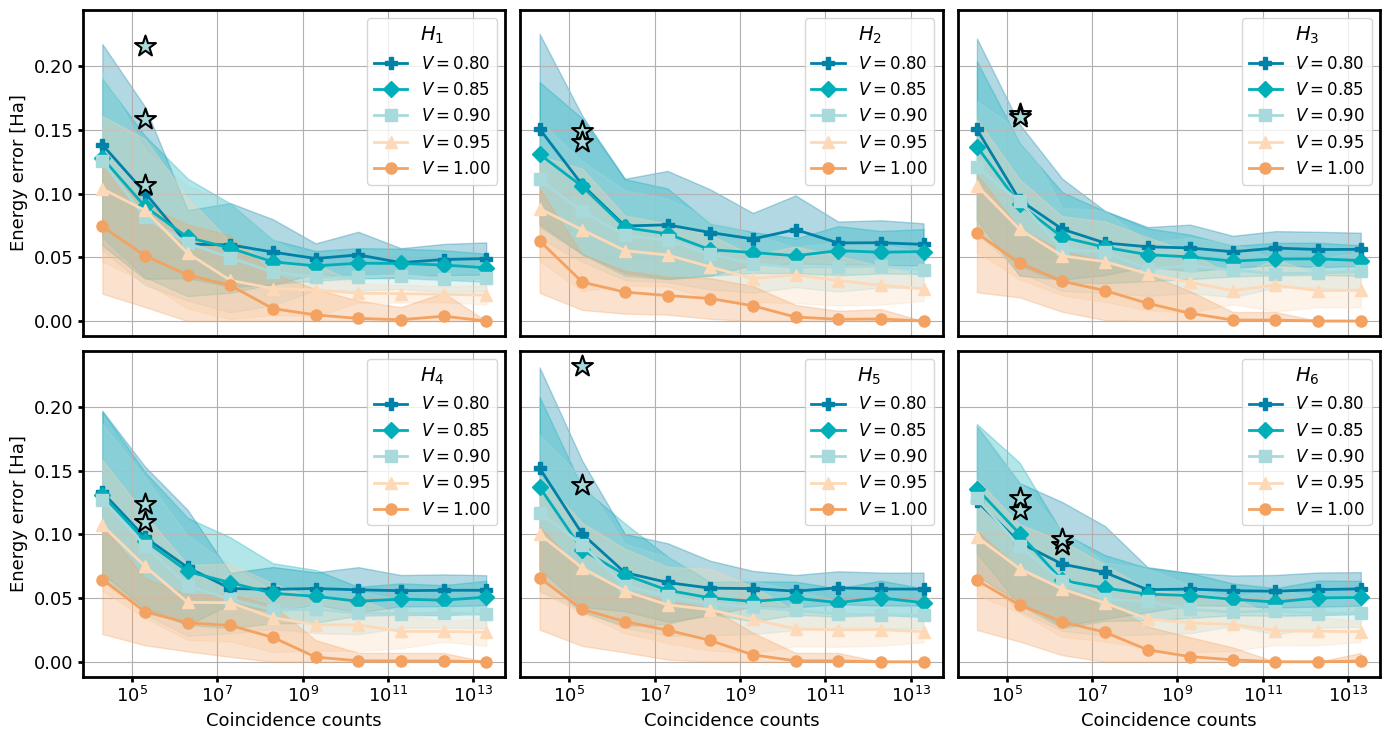

In [ ]:
sim_file = np.load(f'../Simulations/8-mode chip/shots_visibility/simulation_100.npz')
accuracy = sim_file['accuracy']
vis_range = sim_file['visibility']
exposure_range = sim_file['exposure']
N_trials = 100
# accuracy = accuracy[:,:7,:]
# exposure_range = exposure_range[:7]


colors = ['#0081A7',
          '#00AFB9',
          '#A8DADC',
          '#FED9B7',
          '#F4A261',
          '#F07167']

markers = ['P', 'D', 's', '^', 'o', ]



fig, axs = plt.subplots(2, 3, figsize=(14,7.5), sharex=True, sharey=True)

for i, ax in enumerate(axs.flat):
    for j, V in enumerate(vis_range):

        mean = np.mean(accuracy[i,:,j], axis=-1)
        std = np.std(accuracy[i,:,j], axis=-1)

        ax.plot(exposure_range*20_000, mean, marker=markers[j], color=colors[j], lw=2, markersize=8, #markeredgecolor='black', markeredgewidth=0.7,
                label=f'$V = {V:.2f}$', zorder=j + 10)
        ax.fill_between(exposure_range*20_000, np.maximum(mean - std,0), mean + std, color=colors[j], alpha=0.3, zorder=j)

    
    
    ax.set_xscale('log')
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    ax.spines[:].set_linewidth(2)
    ax.tick_params(width=2)
    ax.grid()
    ax.legend(
    title=f'$H_{{{i+1}}}$',
    title_fontsize=14, fontsize=12)
    # ax.set_title(f'$H_{{{i+1}}}$')
    if i < 3:
        ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
    if i >= 3:
        ax.set_xlabel('Coincidence counts', fontsize=13)
    if i % 3 != 0:
        ax.tick_params(axis='y', which='both', left=False, labelleft=False)
    if i % 3 == 0:
        ax.set_ylabel('Energy error [Ha]', fontsize=13)
    ax.tick_params(
    axis='both',
    which='major',
    labelsize=13,
    width=2
    )
    
    ax.tick_params(
        axis='both',
        which='minor',
        width=1.5
    )

axs[0,0].scatter(10*20_000, 0.107020, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)
axs[0,0].scatter(10*20_000, 0.215515, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)
axs[0,0].scatter(10*20_000, 0.158280, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)

axs[0,1].scatter(10*20_000, 0.148800, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)
axs[0,1].scatter(10*20_000, 0.140201, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)

axs[0,2].scatter(10*20_000, 0.162745, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)
axs[0,2].scatter(10*20_000, 0.159777, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)

axs[1,0].scatter(10*20_000, 0.109458, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)
axs[1,0].scatter(10*20_000, 0.123879, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)

axs[1,1].scatter(10*20_000, 0.232360, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)
axs[1,1].scatter(10*20_000, 0.138855, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)

axs[1,2].scatter(10*20_000, 0.118751, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)
axs[1,2].scatter(10*20_000, 0.128322, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)
axs[1,2].scatter(100*20_000, 0.091274, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)
axs[1,2].scatter(100*20_000, 0.096397, marker='*', s=250, facecolor=colors[2], edgecolor='black', linewidth=1.5, zorder=100)


plt.tight_layout()

plt.savefig(f'../Figures/accuracy_exposure_vs_V_{N_trials}_trials.png', dpi=300, bbox_inches='tight')
plt.savefig(f'../Figures/accuracy_exposure_vs_V_{N_trials}_trials.pdf', bbox_inches='tight')